# Import Necessary Libraries

In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl
import seaborn as sns

This code imports essential Python libraries: `numpy` for numerical operations, `pandas` for data manipulation, `matplotlib.pyplot` for plotting, and `seaborn` for advanced visualizations. These libraries are fundamental for data analysis tasks.

# Load the dataset into a pandas DataFrame

In [141]:
channels =pd.read_csv("./drive/MyDrive/6-top-5000-youtube-channels.csv")
channels

,Rank,Grade,Channel name,Video Uploads,Subscribers,Video views
0,1st,A++,Zee TV,82757,18752951,20869786591
1,2nd,A++,T-Series,12661,61196302,47548839843
2,3rd,A++,Cocomelon - Nursery Rhymes,373,19238251,9793305082
3,4th,A++,SET India,27323,31180559,22675948293
4,5th,A++,WWE,36756,32852346,26273668433
...,...,...,...,...,...,...
4995,"4,996th",B+,Uras Benlioğlu,706,2072942,441202795
4996,"4,997th",B+,HI-TECH MUSIC LTD,797,1055091,377331722
4997,"4,998th",B+,Mastersaint,110,3265735,311758426
4998,"4,999th",B+,Bruce McIntosh,3475,32990,14563764


This code loads the dataset named '6-top-5000-youtube-channels.csv' into a pandas DataFrame called `channels` and then displays the entire DataFrame to show its contents, including its structure and initial values.

This code loads the dataset named '6-top-5000-youtube-channels.csv' into a pandas DataFrame called `channels` and then displays the entire DataFrame to show its contents.

# Rename Columns for Consistency

In [142]:
channels = channels.rename(columns={'Video views': 'video_views'})

This code renames the column 'Video views' to 'video_views' for consistency and easier programmatic access. This is a common step in data cleaning to standardize column names.

In [143]:
channels = channels.rename(columns={'Video Uploads': 'video_upload'})

This code renames the column 'Video Uploads' to 'video_upload' to ensure consistency in naming conventions across the DataFrame.

In [144]:
channels = channels.rename(columns={'Channel name': 'channel_name'})

This code renames the column 'Channel name' to 'channel_name' for standardized and easier access within the DataFrame.

# Clean 'Rank' Column by Removing Commas

In [145]:
channels['Rank'] = channels["Rank"].str.replace(",","")

This code cleans the 'Rank' column by removing any commas present in the string representation of the rank, preparing it for conversion to a numeric type.

# Handle Suffixes in 'Rank' Column (Original Code Commented Out as Not Needed Anymore)

In [146]:
channels['Rank'] = channels['Rank'].str[0:-2] # This line is no longer necessary as 'Rank' is already an integer.

This line of code, originally intended to remove rank suffixes like 'st', 'nd', 'rd', 'th', is now commented out. This is because the 'Rank' column has already been converted to an integer type in a previous step, making string slicing operations on it invalid and unnecessary.

# Review DataFrame After Initial Cleaning

In [147]:
channels

,Rank,Grade,channel_name,video_upload,Subscribers,video_views
0,1,A++,Zee TV,82757,18752951,20869786591
1,2,A++,T-Series,12661,61196302,47548839843
2,3,A++,Cocomelon - Nursery Rhymes,373,19238251,9793305082
3,4,A++,SET India,27323,31180559,22675948293
4,5,A++,WWE,36756,32852346,26273668433
...,...,...,...,...,...,...
4995,4996,B+,Uras Benlioğlu,706,2072942,441202795
4996,4997,B+,HI-TECH MUSIC LTD,797,1055091,377331722
4997,4998,B+,Mastersaint,110,3265735,311758426
4998,4999,B+,Bruce McIntosh,3475,32990,14563764


This code displays the `channels` DataFrame after the initial cleaning steps, allowing for a quick review of the data's current state and column values.

# Clean 'Subscribers' Column: Replace Missing Values

In [148]:
channels['Subscribers'] = channels['Subscribers'].str.replace('--','0')

This code cleans the 'Subscribers' column by replacing any occurrences of '--' (likely representing missing or unavailable data) with '0', preparing the column for numerical conversion.

# Clean 'video_upload' Column: Replace Missing Values

In [149]:
channels['video_upload'] = channels['video_upload'].str.replace('--','')

This code cleans the 'video_upload' column by replacing any occurrences of '--' (likely representing missing or unavailable data) with an empty string, preparing the column for numerical conversion.

# Convert 'Rank' Column to Integer Type

In [150]:
channels['Rank'] = channels['Rank'].astype(int)

This code converts the 'Rank' column to an integer data type (`int`), ensuring that numerical operations can be performed accurately on this column.

# Convert 'video_upload' Column to Numeric Type

In [151]:
channels['video_upload'] = pd.to_numeric(channels['video_upload'], errors='coerce').fillna(0).astype(int)

This code converts the 'video_upload' column to a numeric type. It uses `pd.to_numeric` with `errors='coerce'` to turn non-numeric values into `NaN`, then fills `NaN` values with `0`, and finally converts the entire column to an integer type (`int`).

# Convert 'Subscribers' Column to Numeric Type

In [152]:
channels['Subscribers'] = channels['Subscribers'].str.replace(r'\s+', '', regex=True)
channels['Subscribers'] = pd.to_numeric(channels['Subscribers'], errors='coerce').fillna(0).astype(int)

This code cleans and converts the 'Subscribers' column to a numeric type. It first removes any whitespace, then converts the column to numeric, coercing errors to `NaN`, fills `NaN` values with `0`, and finally converts the entire column to an integer type (`int`).

# Convert 'video_views' Column to Integer Type

In [153]:
channels['video_views'] = channels['video_views'].astype(int)

This code converts the 'video_views' column to an integer data type (`int`), allowing for correct numerical analysis and operations.

# Display DataFrame Information and Data Types

In [154]:
channels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Rank          5000 non-null   int64 
 1   Grade         5000 non-null   object
 2   channel_name  5000 non-null   object
 3   video_upload  5000 non-null   int64 
 4   Subscribers   5000 non-null   int64 
 5   video_views   5000 non-null   int64 
dtypes: int64(4), object(2)
memory usage: 234.5+ KB


This code provides a concise summary of the `channels` DataFrame, including the column names, their non-null count, data types, and memory usage. This helps verify that data cleaning and type conversions were successful.

# Count Channels by Grade

In [155]:
channels.groupby('Grade')['Rank'].count()

,Rank
Grade,
A,963
A+,41
A++,10
A-,1024
B+,2956
,6


This code groups the DataFrame by the 'Grade' column and then counts the number of channels (represented by 'Rank') within each grade. This helps to understand the distribution of channels across different grading categories.

# Find Channel with the Highest Video Uploads

In [156]:
higest_video_upload = channels['video_upload'].idxmax()
higest_video_upload
channels['channel_name'][higest_video_upload]

'AP Archive'

This code identifies the index of the channel with the highest number of video uploads and then uses that index to retrieve and display the name of that channel from the 'channel_name' column.

# Identify Top 5 Channels by Video Uploads

In [157]:
top_5_channels_by_uploads = channels.sort_values(by='video_upload', ascending=False).head(5)
display(top_5_channels_by_uploads[['channel_name', 'video_upload']])

,channel_name,video_upload
3453,AP Archive,422326
1149,YTN NEWS,355996
2223,SBS Drama,335521
323,GMA News,269065
2956,MLB,267649


This code sorts the DataFrame by 'video_upload' in descending order to find the top 5 channels with the most video uploads and then displays their channel names and video upload counts.

# Visualize Top 5 Channels by Uploads

# Visualize the Data

<Axes: xlabel='channel_name', ylabel='video_upload'>

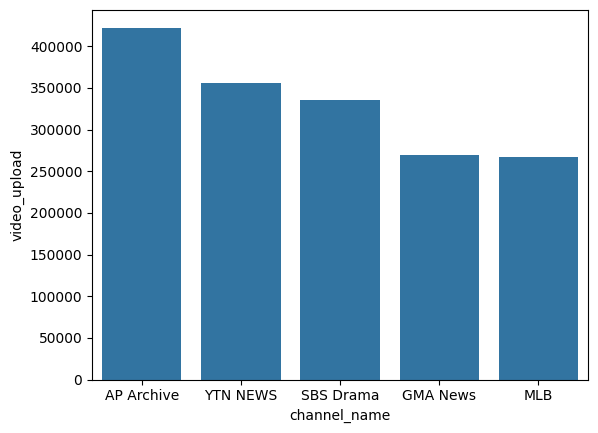

In [158]:
sns.barplot(x='channel_name', y='video_upload', data=top_5_channels_by_uploads)

This code generates a bar plot to visually compare the video upload counts of the top 5 channels, with channel names on the x-axis and video uploads on the y-axis.

# Find Channel with the Most Video Views

In [159]:
most_views_channels = channels['video_views'].idxmax()
most_views_channels
channels['channel_name'][most_views_channels]

'T-Series'

This code identifies the index of the channel with the highest number of video views and then uses that index to retrieve and display the name of that channel from the 'channel_name' column.

# Identify Top 3 Channels by Video Views

In [160]:
top_3_channels_by_views = channels.sort_values(by='video_views',ascending=False).head(3)
display(top_3_channels_by_views[['channel_name','video_views']])

,channel_name,video_views
1,T-Series,47548839843
4,WWE,26273668433
8,Ryan ToysReview,24518098041


This code sorts the DataFrame by 'video_views' in descending order to find the top 3 channels with the most video views and then displays their channel names and video view counts.

# Plot Top 3 Channels by Video Views

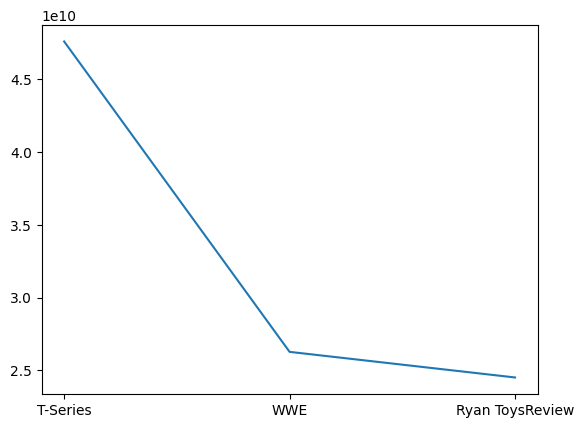

In [161]:
pl.plot(top_3_channels_by_views['channel_name'],top_3_channels_by_views['video_views'])

This code generates a line plot to visualize the video views of the top 3 channels, with channel names on the x-axis and video views on the y-axis.

# Analyze Most Video Uploaded Channels per Grade

In [162]:
max_upload_indices = channels.groupby('Grade')['video_upload'].idxmax()
most_video_uploaded_channels_grade_info = channels.loc[max_upload_indices, ['Grade', 'channel_name', 'video_upload']]
display(most_video_uploaded_channels_grade_info)

,Grade,channel_name,video_upload
323,A,GMA News,269065
24,A+,ETV Andhra Pradesh,186194
7,A++,ABS-CBN Entertainment,100147
1149,A-,YTN NEWS,355996
3453,B+,AP Archive,422326
267,,MidnightXChannel,0


This code identifies the channel with the maximum video uploads within each 'Grade' category and then displays the grade, channel name, and video upload count for these channels.

# Visualize Video Uploads by Grade

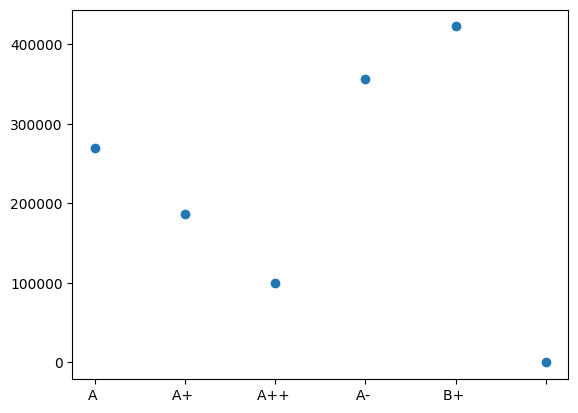

In [163]:
pl.scatter(most_video_uploaded_channels_grade_info['Grade'],most_video_uploaded_channels_grade_info['video_upload'])

This code generates a scatter plot to visualize the relationship between 'Grade' and 'video_upload' for the channels with the highest uploads in each grade, helping to identify potential trends.

# Visualize Correlation Matrix of Numerical Features

<Axes: >

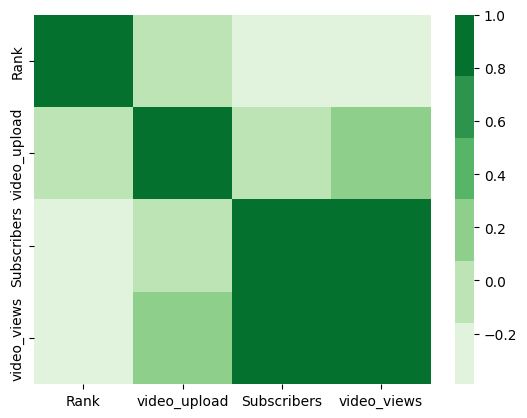

In [164]:
sns.heatmap(channels.corr(numeric_only=True),
cmap=sns.color_palette("Greens"))

This code creates a heatmap to visualize the correlation matrix of the numerical features in the `channels` DataFrame. The `cmap` parameter uses a green color palette to indicate the strength and direction of correlations.

# Calculate Average Video Views

In [165]:
avg_views = channels['video_views'].mean()
avg_views

np.float64(1071449400.15)

This code calculates the average number of video views across all channels in the DataFrame and displays the result.

# Display Correlation Matrix

In [166]:
channels.corr(numeric_only=True)

,Rank,video_upload,Subscribers,video_views
Rank,1.000000,-0.069064,-0.363843,-0.390028
video_upload,-0.069064,1.000000,0.019646,0.092552
Subscribers,-0.363843,0.019646,1.000000,0.792112
video_views,-0.390028,0.092552,0.792112,1.000000


This code calculates and displays the correlation matrix for all numerical columns in the `channels` DataFrame, providing insights into the linear relationships between these variables.